In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from skimage import data

Image size: 512 x 512


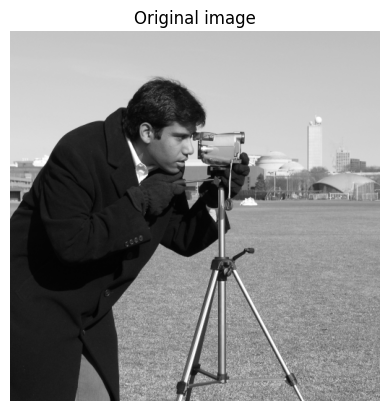

In [ ]:
img = data.camera().astype(float)
M, N = img.shape
print('Image size:', M, 'x', N)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original image'); plt.axis('off'); plt.show()

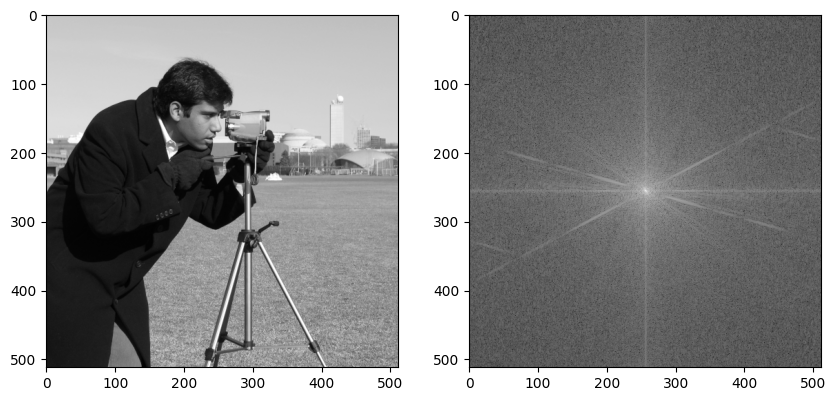

In [ ]:
from typing import ChainMap
F =np.fft.fftshift(np.fft.fft2(img))
spectrum = np.log(1+np.abs(F))
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img, cmap='gray')
axs[1].imshow(spectrum, cmap='gray')
plt.show()

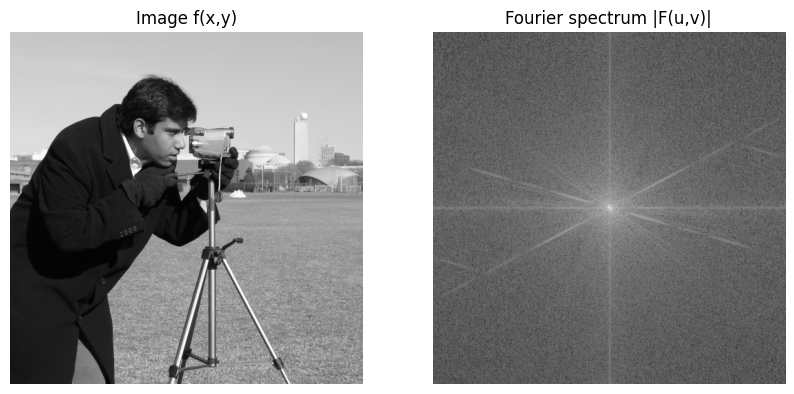

In [ ]:
F = np.fft.fftshift(np.fft.fft2(img))
spectrum = np.log(1 + np.abs(F))
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img, cmap='gray'); axs[0].set_title('Image f(x,y)')
axs[1].imshow(spectrum, cmap='gray'); axs[1].set_title('Fourier spectrum |F(u,v)|')
for a in axs: a.axis('off')
plt.show()

In [ ]:

u = np.arange(M)
v = np.arange(N)
V, U = np.meshgrid(v, u)
D = np.sqrt((U - M/2)**2 + (V - N/2)**2)

def filter_image(H):
    """Steps 2 and 3: G = H*F, then inverse DFT."""
    G = H * F
    g = np.real(np.fft.ifft2(np.fft.ifftshift(G)))
    return g

def show_grid(images, titles, cols=3, cmap='gray'):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(4*cols, 4*rows))
    for i, (im, ti) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i+1)
        plt.imshow(im, cmap=cmap, vmin=0, vmax=255 if im.max() > 2 else 1)
        plt.title(ti, fontsize=10); plt.axis('off')
    plt.tight_layout(); plt.show()

def show_spectrum_with_circles(radii):
    """Spectrum with the filter radii drawn on top (Slide 22)."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(spectrum, cmap='gray')
    for r in radii:
        ax.add_patch(Circle((N/2, M/2), r, fill=False, color='yellow', lw=1))
    ax.set_title('Spectrum with filter radii'); ax.axis('off')
    plt.show()

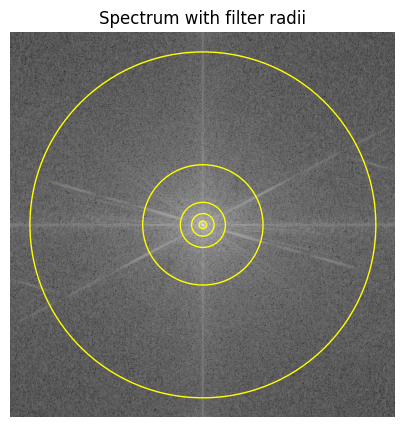

In [ ]:
radii = [5, 15, 30, 80, 230]
show_spectrum_with_circles(radii)

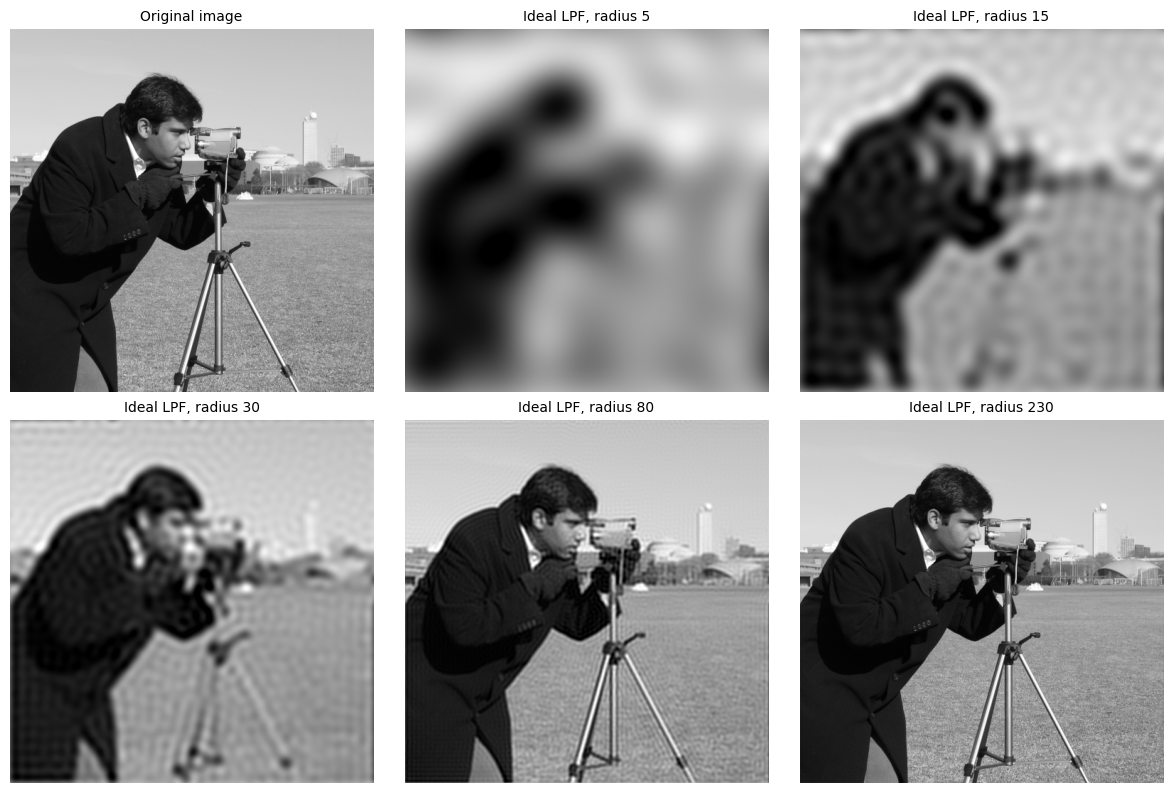

In [ ]:
def ideal_lpf(D, D0):
    return np.where(D <= D0, 1.0, 0.0)

ideal_results = [img]
ideal_titles = ['Original image']
for D0 in radii:
    H = ideal_lpf(D, D0)
    ideal_results.append(filter_image(H))
    ideal_titles.append(f'Ideal LPF, radius {D0}')

show_grid(ideal_results, ideal_titles)

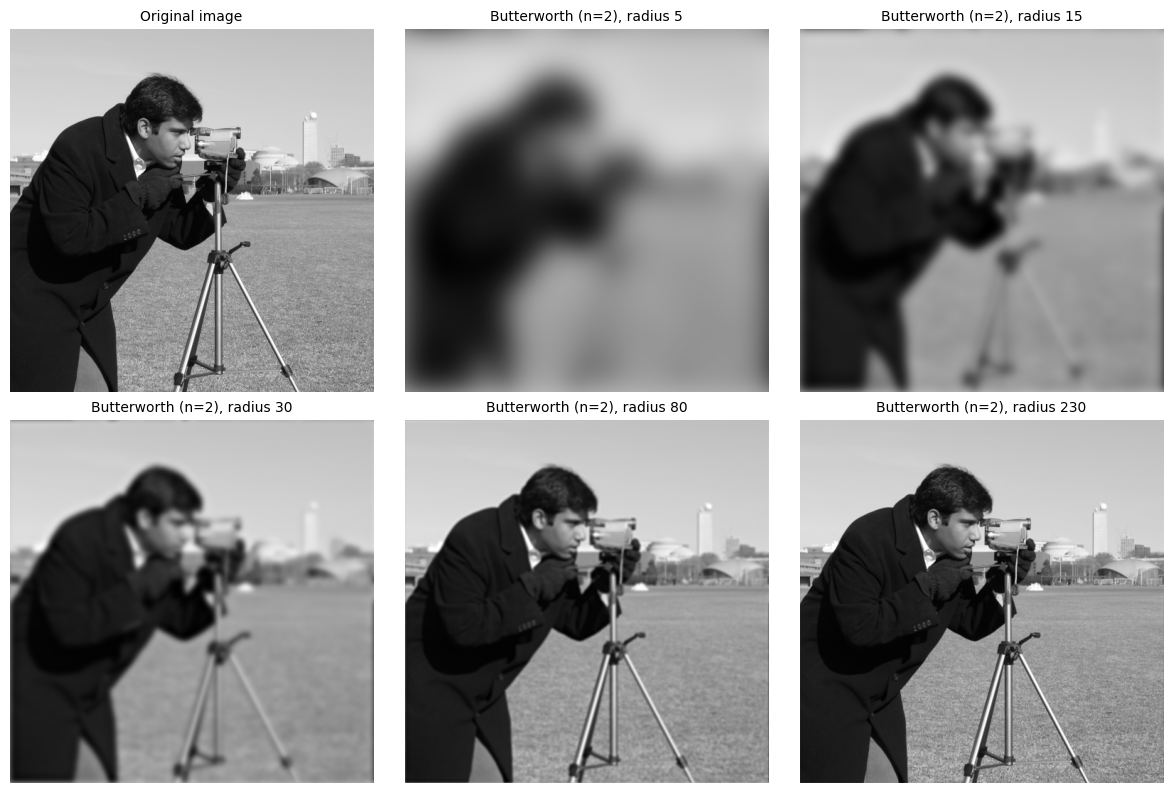

In [ ]:
def butterworth_lpf(D, D0, n=2):
    return 1.0 / (1.0 + (D / D0)**(2*n))
bw_results = [img]
bw_titles = ['Original image']
for D0 in radii:
    H = butterworth_lpf(D, D0, n=2)
    bw_results.append(filter_image(H))
    bw_titles.append(f'Butterworth (n=2), radius {D0}')

show_grid(bw_results, bw_titles)

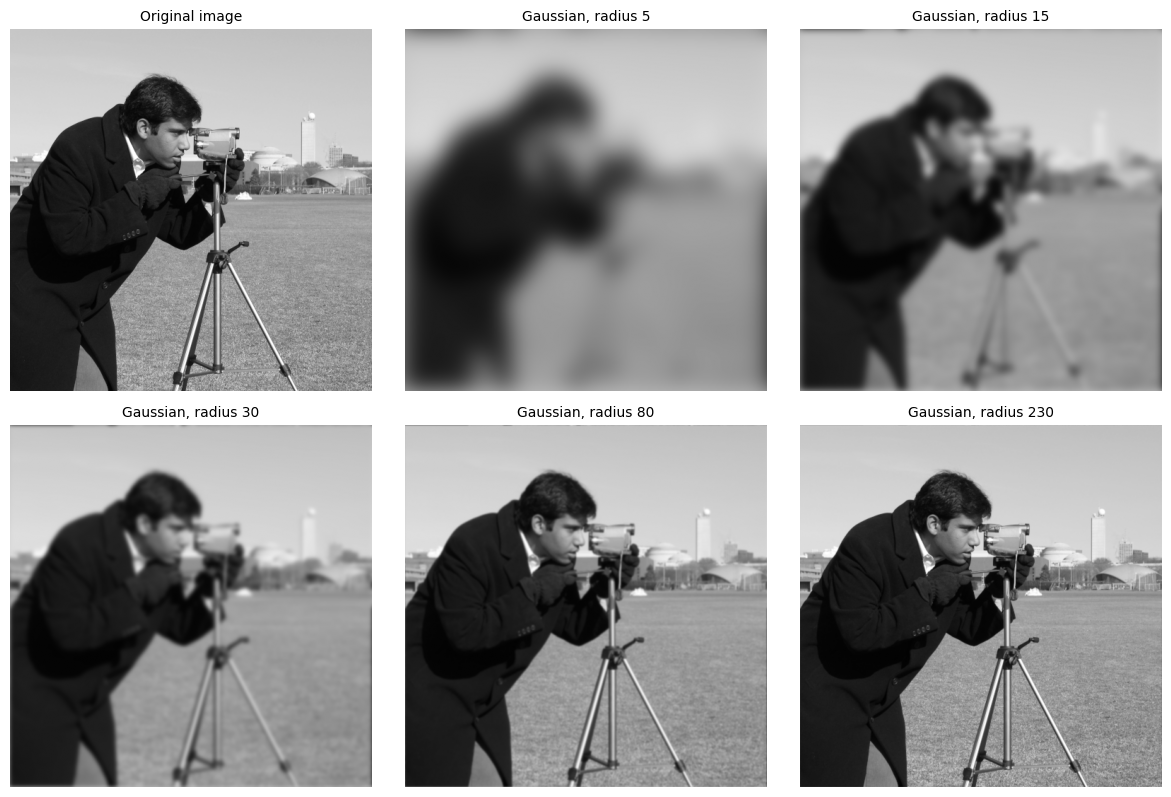

In [ ]:
def gaussian_lpf(D, D0):
    return np.exp(-(D**2) / (2 * D0**2))
    gauss_results = [img]
gauss_titles = ['Original image']
for D0 in radii:
    H = gaussian_lpf(D, D0)
    gauss_results.append(filter_image(H))
    gauss_titles.append(f'Gaussian, radius {D0}')

show_grid(gauss_results, gauss_titles)

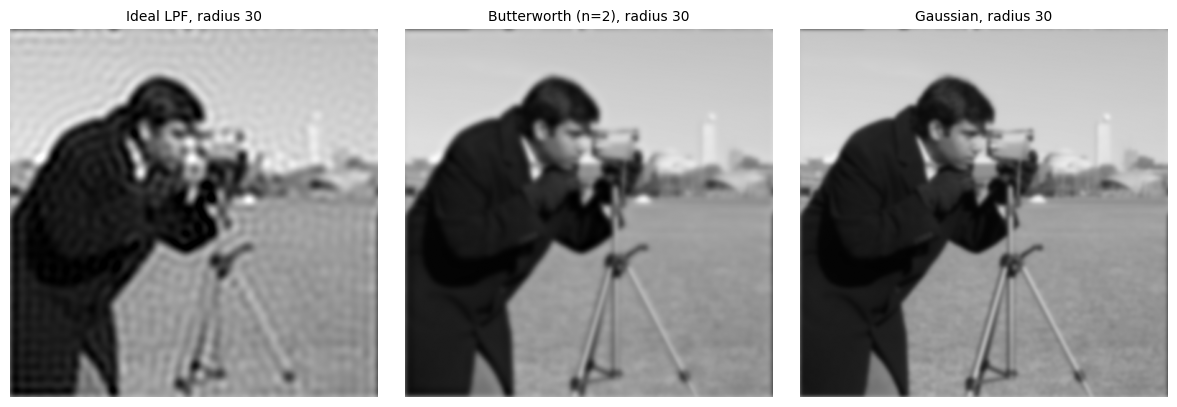

In [ ]:
cmp_imgs = [filter_image(ideal_lpf(D, 30)),
            filter_image(butterworth_lpf(D, 30, n=2)),
            filter_image(gaussian_lpf(D, 30))]
cmp_titles = ['Ideal LPF, radius 30', 'Butterworth (n=2), radius 30', 'Gaussian, radius 30']
show_grid(cmp_imgs, cmp_titles)

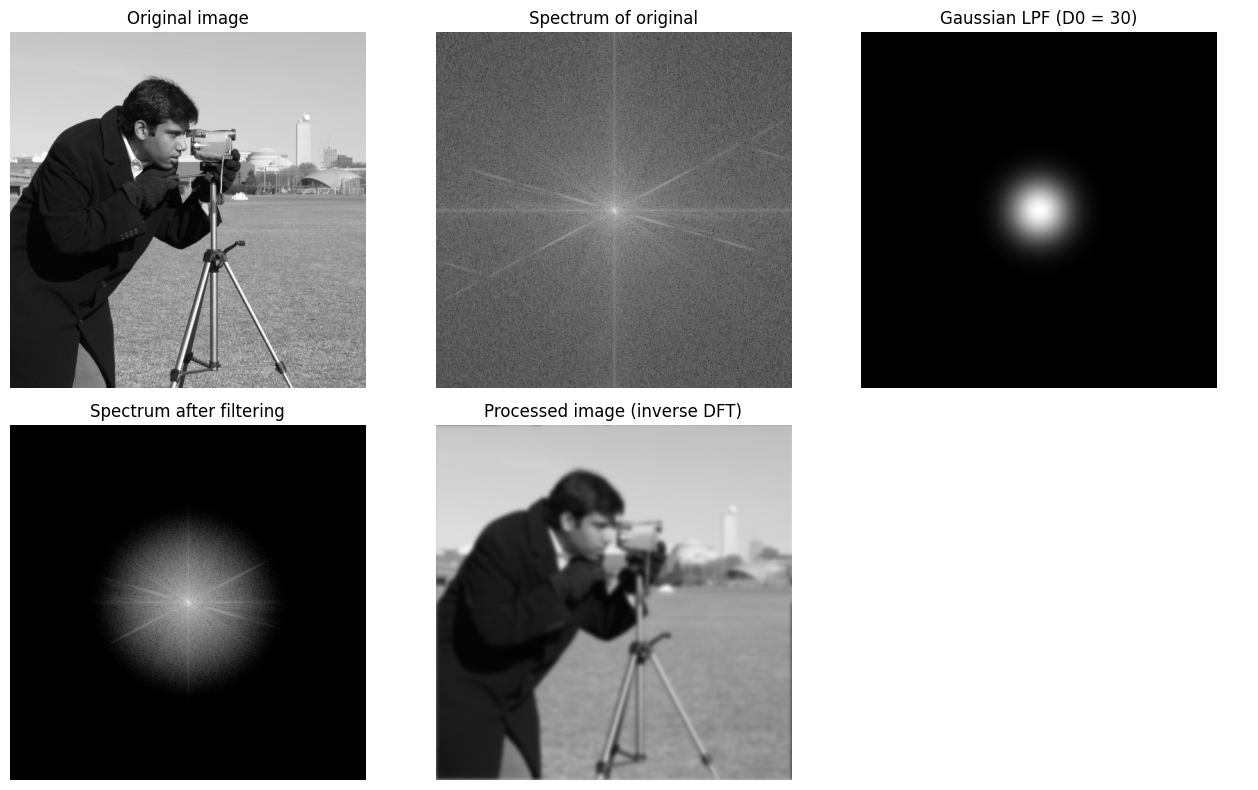

In [ ]:
H = gaussian_lpf(D, 30)
filtered_spectrum = np.log(1 + np.abs(H * F))
processed = filter_image(H)

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
axs[0,0].imshow(img, cmap='gray');               axs[0,0].set_title('Original image')
axs[0,1].imshow(spectrum, cmap='gray');          axs[0,1].set_title('Spectrum of original')
axs[0,2].imshow(H, cmap='gray');                 axs[0,2].set_title('Gaussian LPF (D0 = 30)')
axs[1,0].imshow(filtered_spectrum, cmap='gray'); axs[1,0].set_title('Spectrum after filtering')
axs[1,1].imshow(processed, cmap='gray', vmin=0, vmax=255); axs[1,1].set_title('Processed image (inverse DFT)')
axs[1,2].axis('off')
for a in axs.ravel(): a.axis('off')
plt.tight_layout(); plt.show()